<a href="https://colab.research.google.com/github/abdulghaffark2425/Datheon_Python_Programming_Internship/blob/main/Task02_RealEstate_Housing_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Step 1: Loading Dataset & Handling Nulls ===
Dataset Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedianHouseValue']
Dataset Shape: (20640, 9)

=== Step 2: Feature Engineering & Correlation Heatmap ===


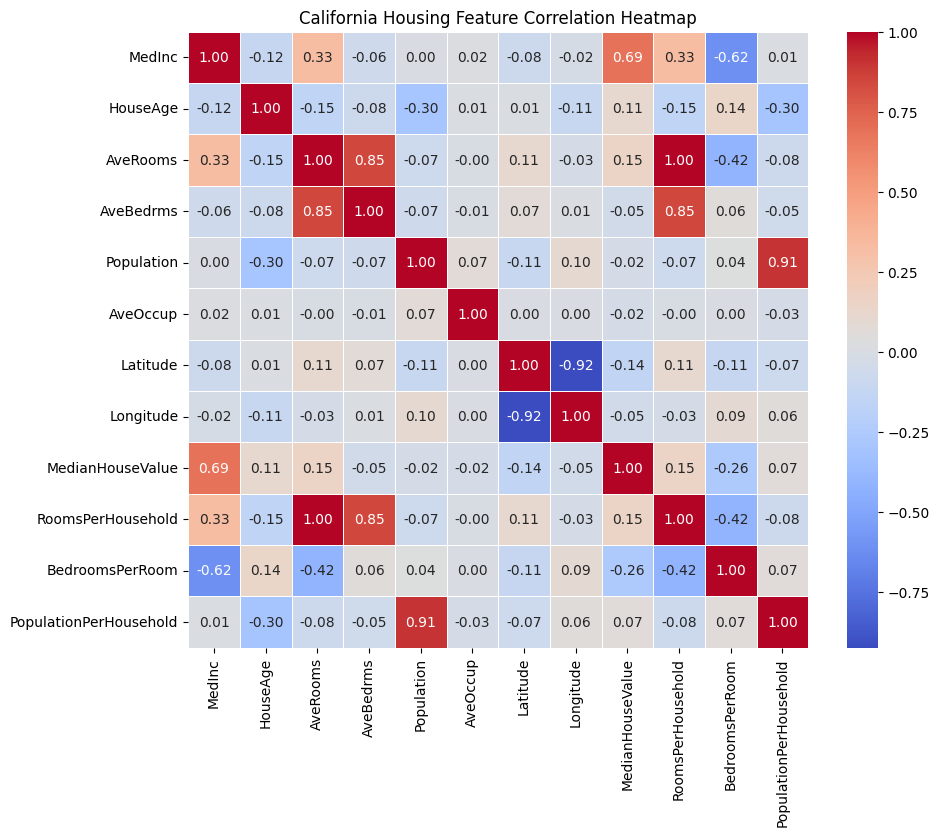


=== Step 3: Dataset Splitting & Standardization ===
Training Samples: 16512 | Testing Samples: 4128

=== Step 4: Model Training & Hyperparameter Tuning ===
Best Ridge Alpha: 50.0
Best Lasso Alpha: 0.01

=== Step 5: Model Evaluation Comparison ===
                Model     RMSE      MAE  R2 Score
OLS Linear Regression 0.695842 0.503022   0.63050
Ridge Regression (L2) 0.696097 0.502947   0.63023
Lasso Regression (L1) 0.700366 0.505954   0.62568

=== Step 6: Plotting Prediction Performance & Residual Errors ===


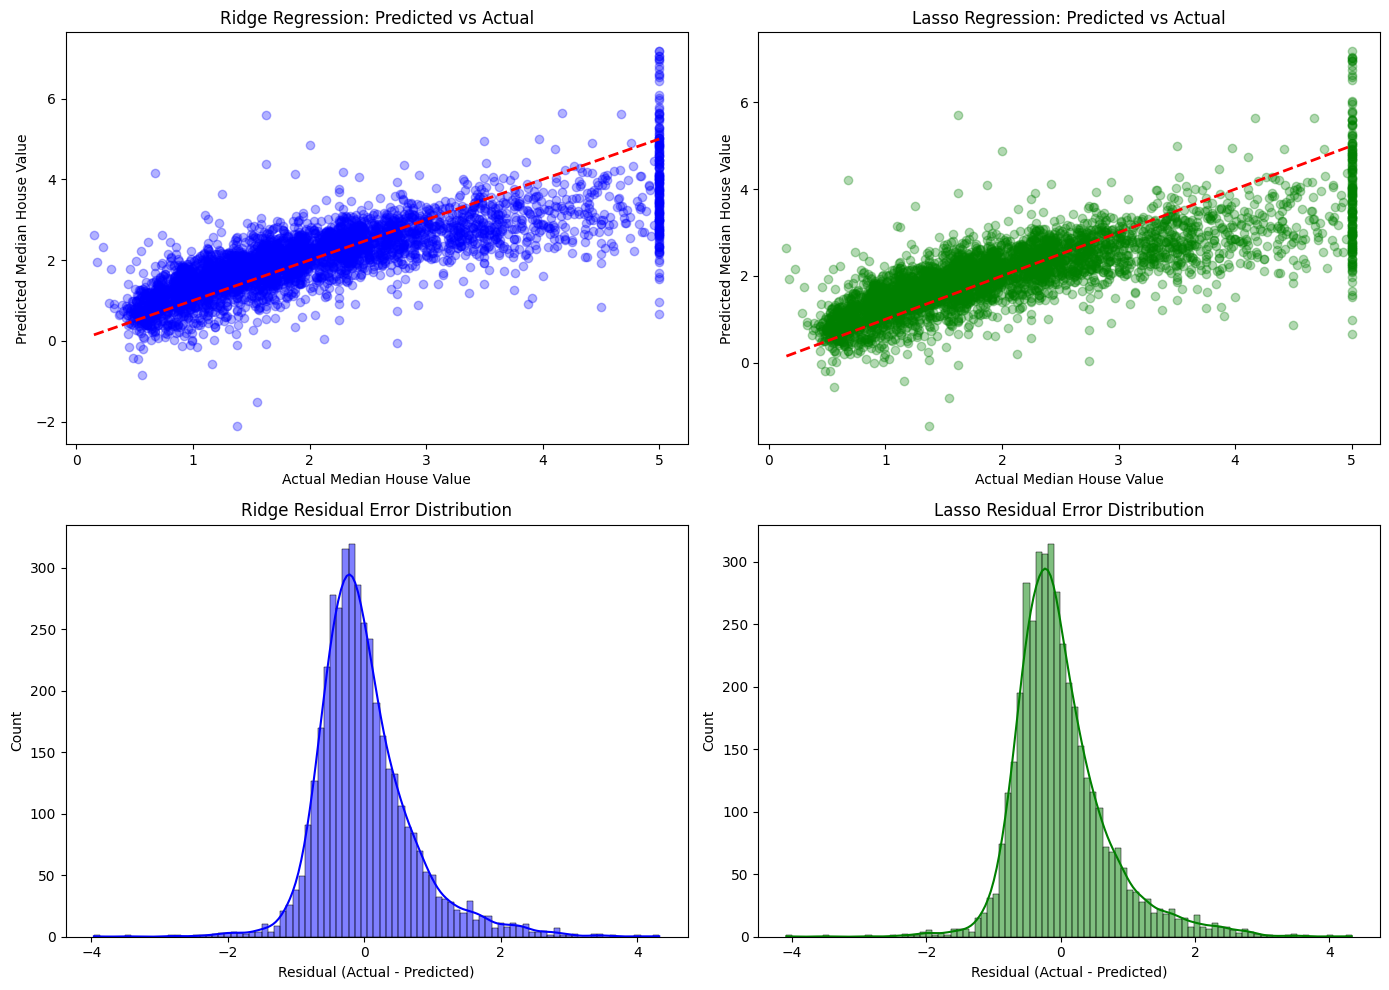

In [ ]:
# =========================================================
# DATHEON ML INTERNSHIP - TASK 02 (FIXED)
# Real Estate Housing Price Prediction (Ridge & Lasso)
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ---------------------------------------------------------
# STEP 1: Load California Housing Dataset & Impute Missing Values
# ---------------------------------------------------------
print("=== Step 1: Loading Dataset & Handling Nulls ===")
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# Target Column rename
df.rename(columns={'MedHouseVal': 'MedianHouseValue'}, inplace=True)

print("Dataset Columns:", df.columns.tolist())
print("Dataset Shape:", df.shape)

# Impute null values (if any)
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

# ---------------------------------------------------------
# STEP 2: Feature Engineering & Correlation Heatmap
# ---------------------------------------------------------
print("\n=== Step 2: Feature Engineering & Correlation Heatmap ===")

# Interaction Features (Using Exact Dataset Column Names)
df_imputed['RoomsPerHousehold'] = df_imputed['AveRooms']
df_imputed['BedroomsPerRoom'] = df_imputed['AveBedrms'] / df_imputed['AveRooms']
df_imputed['PopulationPerHousehold'] = df_imputed['Population'] / df_imputed['AveOccup']

# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_imputed.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title("California Housing Feature Correlation Heatmap")
plt.show()

# ---------------------------------------------------------
# STEP 3: Train/Test Split (80/20) & Feature Standardization
# ---------------------------------------------------------
print("\n=== Step 3: Dataset Splitting & Standardization ===")
X = df_imputed.drop(columns=['MedianHouseValue'])
y = df_imputed['MedianHouseValue']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Samples: {X_train.shape[0]} | Testing Samples: {X_test.shape[0]}")

# ---------------------------------------------------------
# STEP 4: Fit OLS, Ridge & Lasso with GridSearchCV Tuning
# ---------------------------------------------------------
print("\n=== Step 4: Model Training & Hyperparameter Tuning ===")

# 1. OLS Linear Regression
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)
y_pred_ols = ols_model.predict(X_test_scaled)

# 2. Ridge Regression (L2)
param_grid = {'alpha': [0.01, 0.1, 1.0, 10.0, 50.0, 100.0]}
ridge_grid = GridSearchCV(Ridge(random_state=42), param_grid, cv=5, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train_scaled, y_train)
best_ridge = ridge_grid.best_estimator_
y_pred_ridge = best_ridge.predict(X_test_scaled)

# 3. Lasso Regression (L1)
lasso_grid = GridSearchCV(Lasso(random_state=42, max_iter=5000), param_grid, cv=5, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train_scaled, y_train)
best_lasso = lasso_grid.best_estimator_
y_pred_lasso = best_lasso.predict(X_test_scaled)

print(f"Best Ridge Alpha: {ridge_grid.best_params_['alpha']}")
print(f"Best Lasso Alpha: {lasso_grid.best_params_['alpha']}")

# ---------------------------------------------------------
# STEP 5: Benchmarking Model Metrics (RMSE, MAE, R²)
# ---------------------------------------------------------
print("\n=== Step 5: Model Evaluation Comparison ===")

def calculate_metrics(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'Model': model_name, 'RMSE': rmse, 'MAE': mae, 'R2 Score': r2}

metrics_list = [
    calculate_metrics(y_test, y_pred_ols, "OLS Linear Regression"),
    calculate_metrics(y_test, y_pred_ridge, "Ridge Regression (L2)"),
    calculate_metrics(y_test, y_pred_lasso, "Lasso Regression (L1)")
]

results_df = pd.DataFrame(metrics_list)
print(results_df.to_string(index=False))

# ---------------------------------------------------------
# STEP 6: Visualizations (Predicted vs Actual & Residual Analysis)
# ---------------------------------------------------------
print("\n=== Step 6: Plotting Prediction Performance & Residual Errors ===")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Predicted vs Actual (Ridge)
axes[0, 0].scatter(y_test, y_pred_ridge, alpha=0.3, color='blue')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 0].set_title("Ridge Regression: Predicted vs Actual")
axes[0, 0].set_xlabel("Actual Median House Value")
axes[0, 0].set_ylabel("Predicted Median House Value")

# 2. Predicted vs Actual (Lasso)
axes[0, 1].scatter(y_test, y_pred_lasso, alpha=0.3, color='green')
axes[0, 1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0, 1].set_title("Lasso Regression: Predicted vs Actual")
axes[0, 1].set_xlabel("Actual Median House Value")
axes[0, 1].set_ylabel("Predicted Median House Value")

# 3. Residual Error Distribution (Ridge)
residuals_ridge = y_test - y_pred_ridge
sns.histplot(residuals_ridge, kde=True, ax=axes[1, 0], color='blue')
axes[1, 0].set_title("Ridge Residual Error Distribution")
axes[1, 0].set_xlabel("Residual (Actual - Predicted)")

# 4. Residual Error Distribution (Lasso)
residuals_lasso = y_test - y_pred_lasso
sns.histplot(residuals_lasso, kde=True, ax=axes[1, 1], color='green')
axes[1, 1].set_title("Lasso Residual Error Distribution")
axes[1, 1].set_xlabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()